# Apache Hadoop — Projeto Integrado de Telemetria de Jogos

**Equipe 4 | Big Data**

## Objetivo

Demonstrar o armazenamento e o processamento de dados de telemetria de jogos utilizando conceitos do ecossistema Apache Hadoop.

O projeto utiliza dados tratados de jogadores, sessões, partidas, itens e compras.

In [69]:
import os
import sys
import shutil
import platform
import subprocess
import sqlite3
from pathlib import Path
from collections import defaultdict
import matplotlib.pyplot as plt

import pandas as pd
from IPython.display import display

## Preparação do ambiente

O projeto utiliza caminhos relativos ao repositório para permitir sua execução em diferentes computadores.
Os arquivos CSV devem estar na pasta:
`big_data/data_lake/processed/`
O notebook procura automaticamente a raiz do projeto, independentemente do nome do usuário do computador.

In [70]:
def localizar_projeto():
    pasta = Path.cwd().resolve()

    for candidata in [pasta, *pasta.parents]:
        if (candidata / "big_data").is_dir():
            return candidata

    raise FileNotFoundError(
        "Pasta 'big_data' não encontrada. "
        "Abra o repositório do projeto no VS Code."
    )


PROJETO = localizar_projeto()
DADOS = PROJETO / "big_data" / "data_lake" / "processed"

ARQUIVOS = {
    "sessoes": "sessoes_limpo.csv",
    "jogadores": "jogadores_limpo.csv",
    "partidas": "partidas_limpo.csv",
    "compras": "compras_limpo.csv",
    "itens_compras": "itens_compras_limpo.csv",
    "itens": "itens_limpo.csv",
}

print("Raiz do projeto:", PROJETO)
print("Pasta dos dados:", DADOS)

for nome, arquivo in ARQUIVOS.items():
    caminho = DADOS / arquivo
    print(f"{nome}: {'OK' if caminho.is_file() else 'AUSENTE'}")

Raiz do projeto: C:\Users\Windows\Projeto_Data_Science_Equipe4_Principal
Pasta dos dados: C:\Users\Windows\Projeto_Data_Science_Equipe4_Principal\big_data\data_lake\processed
sessoes: OK
jogadores: OK
partidas: OK
compras: OK
itens_compras: OK
itens: OK


In [71]:
dados = {}

for nome, arquivo in ARQUIVOS.items():
    caminho = DADOS / arquivo

    if caminho.is_file():
        dados[nome] = pd.read_csv(caminho)

print("Tabelas carregadas:", len(dados))

df_sessoes = dados["sessoes"]
df_jogadores = dados["jogadores"]
df_partidas = dados["partidas"]
df_compras = dados["compras"]
df_itens_compras = dados["itens_compras"]
df_itens = dados["itens"]

display(df_sessoes.head())

Tabelas carregadas: 6


,sessao_id,player_id,data_inicio_sessao,data_fim_sessao,duracao_minutos,plataforma,genero_jogo,nivel_inicio,nivel_fim
0,1,1,2026-06-03 12:38:17,2026-06-03 13:58:17,80,PlayStation,Aventura,1,5
1,2,1,2026-07-26 08:04:49,2026-07-26 11:04:49,180,PC,Simulação,5,9
2,3,1,2026-08-22 11:36:08,2026-08-22 14:53:08,197,PlayStation,Simulação,9,13
3,4,1,2026-09-03 08:30:16,2026-09-03 10:13:16,103,PC,Aventura,13,17
4,5,1,2026-09-04 05:26:13,2026-09-04 08:52:13,206,PlayStation,Simulação,17,21


In [72]:
resumo = []

for nome, df in dados.items():
    resumo.append({
        "tabela": nome,
        "linhas": len(df),
        "colunas": len(df.columns),
        "duplicatas": int(df.duplicated().sum())
    })

df_resumo = pd.DataFrame(resumo)

display(df_resumo)

,tabela,linhas,colunas,duplicatas
0,sessoes,37366,9,0
1,jogadores,1000,11,0
2,partidas,58312,8,0
3,compras,1425,3,0
4,itens_compras,1963,8,0
5,itens,37,5,0


## 2. HDFS — Hadoop Distributed File System

O HDFS é o sistema de arquivos distribuído do Hadoop.

Seus principais componentes são:
- **NameNode:** controla os metadados dos arquivos.
- **DataNode:** armazena os blocos dos arquivos.
- **Replicação:** permite manter cópias dos blocos.

In [73]:
def comando_hadoop(programa, argumentos=None):
    argumentos = argumentos or []

    if platform.system() == "Windows":
        if not shutil.which("wsl"):
            return None, "WSL não disponível."

        import shlex

        comando_linux = (
            'HADOOP_BIN="${HADOOP_HOME:+$HADOOP_HOME/bin/}"; '
            'if [ -z "$HADOOP_BIN" ]; then '
            'HADOOP_BIN=""; fi; '
            + shlex.quote(programa)
        )

        # Primeiro procurar o executável no PATH do WSL.
        # Se não estiver disponível, usar HADOOP_HOME.
        args_linux = " ".join(
            shlex.quote(str(arg))
            for arg in argumentos
        )

        script = (
            'if command -v ' + shlex.quote(programa)
            + ' >/dev/null 2>&1; then '
            + shlex.quote(programa) + ' ' + args_linux
            + '; elif [ -n "$HADOOP_HOME" ] '
            + '&& [ -x "$HADOOP_HOME/bin/'
            + programa + '" ]; then '
            + '"$HADOOP_HOME/bin/' + programa + '" '
            + args_linux
            + '; else echo "Hadoop não encontrado no PATH '
            + 'ou HADOOP_HOME" >&2; exit 127; fi'
        )

        comando = ["wsl", "bash", "-lc", script]

    else:
        executavel = shutil.which(programa)

        if not executavel:
            home = os.environ.get("HADOOP_HOME")

            if home:
                candidato = Path(home) / "bin" / programa

                if candidato.is_file():
                    executavel = str(candidato)

        if not executavel:
            return None, f"{programa} não encontrado."

        comando = [executavel, *map(str, argumentos)]

    try:
        resultado = subprocess.run(
            comando,
            capture_output=True,
            text=True,
            encoding="utf-8",
            errors="replace",
            timeout=120
        )

        if resultado.returncode == 0:
            return resultado.stdout, None

        return None, resultado.stderr.strip()

    except (OSError, subprocess.TimeoutExpired) as erro:
        return None, str(erro)
print("Função de acesso ao Hadoop preparada.")

Função de acesso ao Hadoop preparada.


In [74]:
saida_hdfs, erro_hdfs = comando_hadoop(
    "hdfs",
    ["dfs", "-ls", "-h", "/telemetria/limpos"]
)

if erro_hdfs is None:
    print("HDFS disponível:")
    print(saida_hdfs)
else:
    print("HDFS indisponível nesta execução.")
    print("Detalhes:", erro_hdfs)
    print("As análises locais continuam disponíveis.")

HDFS indisponível nesta execução.
Detalhes: Hadoop não encontrado no PATH ou HADOOP_HOME
As análises locais continuam disponíveis.


In [75]:
for nome, arquivo in ARQUIVOS.items():
    caminho = DADOS / arquivo

    if caminho.is_file():
        tamanho_mb = caminho.stat().st_size / (1024 ** 2)

        print(
            f"{arquivo}: {tamanho_mb:.2f} MB"
        )


sessoes_limpo.csv: 2.75 MB
jogadores_limpo.csv: 0.11 MB
partidas_limpo.csv: 4.10 MB
compras_limpo.csv: 0.04 MB
itens_compras_limpo.csv: 0.06 MB
itens_limpo.csv: 0.00 MB


### Resultado do armazenamento

Os seis arquivos tratados do projeto foram armazenados no HDFS:

`compras_limpo.csv`
`itens_compras_limpo.csv`
`itens_limpo.csv`
`jogadores_limpo.csv`
`partidas_limpo.csv`
`sessoes_limpo.csv`

A execução real do Hadoop confirmou o armazenamento desses arquivos.

## MapReduce — Processamento de sessões

O MapReduce é um modelo de processamento de grandes volumes de dados.

In [76]:
def mapper(generos):
    resultado = []

    for genero in generos:
        if pd.notna(genero):
            genero = str(genero).strip()

            if genero:
                resultado.append((genero, 1))

    return resultado


mapeado = mapper(df_sessoes["genero_jogo"])

print("Registros mapeados:", len(mapeado))
print("Exemplo:", mapeado[:5])

Registros mapeados: 37366
Exemplo: [('Aventura', 1), ('Simulação', 1), ('Simulação', 1), ('Aventura', 1), ('Simulação', 1)]


In [77]:
def shuffle(pares):
    agrupados = defaultdict(list)

    for chave, valor in pares:
        agrupados[chave].append(valor)

    return dict(agrupados)


agrupados = shuffle(mapeado)

print("Gêneros encontrados:", len(agrupados))


Gêneros encontrados: 11


In [78]:
def reducer(grupos):
    return {
        chave: sum(valores)
        for chave, valores in grupos.items()
    }


reduzido = reducer(agrupados)

df_mapreduce = pd.DataFrame(
    [
        {"genero_jogo": genero, "quantidade_sessoes": total}
        for genero, total in reduzido.items()
    ]
).sort_values(
    "quantidade_sessoes",
    ascending=False
).reset_index(drop=True)

display(df_mapreduce)

print(
    "Total de sessões:",
    df_mapreduce["quantidade_sessoes"].sum()
)

,genero_jogo,quantidade_sessoes
0,FPS,4516
1,Estratégia,3836
2,Esportes,3565
3,Corrida,3409
4,Ação,3397
5,Luta,3225
6,Survival,3202
7,Aventura,3168
8,MOBA,3043
9,Simulação,3040


Total de sessões: 37366


### Execução real no Hadoop

Além da demonstração didática em Python, o projeto executou o MapReduce real utilizando Hadoop Streaming.

In [79]:
resultado_historico = {
    "Aventura": 3168,
    "Ação": 3397,
    "Corrida": 3409,
    "Esportes": 3565,
    "Estratégia": 3836,
    "FPS": 4516,
    "Luta": 3225,
    "MOBA": 3043,
    "RPG": 2965,
    "Simulação": 3040,
    "Survival": 3202
}

saida_real, erro_real = comando_hadoop(
    "hdfs",
    [
        "dfs",
        "-cat",
        "/telemetria/resultados/sessoes_por_genero/part-00000"
    ]
)

if erro_real is None:
    registros = []

    for linha in saida_real.strip().splitlines():
        partes = linha.split("\t")

        if len(partes) == 2:
            registros.append({
                "genero_jogo": partes[0],
                "quantidade_sessoes": int(partes[1])
            })

    df_resultado_hadoop = pd.DataFrame(registros)
    origem_resultado = "Consulta atual ao HDFS"

else:
    df_resultado_hadoop = pd.DataFrame([
        {
            "genero_jogo": genero,
            "quantidade_sessoes": quantidade
        }
        for genero, quantidade in resultado_historico.items()
    ])

    origem_resultado = (
        "Resultado histórico da execução Hadoop "
        "de 05/11/2026"
    )

df_resultado_hadoop = (
    df_resultado_hadoop
    .sort_values("quantidade_sessoes", ascending=False)
    .reset_index(drop=True)
)

print("Origem:", origem_resultado)
display(df_resultado_hadoop)


Origem: Resultado histórico da execução Hadoop de 05/11/2026


,genero_jogo,quantidade_sessoes
0,FPS,4516
1,Estratégia,3836
2,Esportes,3565
3,Corrida,3409
4,Ação,3397
5,Luta,3225
6,Survival,3202
7,Aventura,3168
8,MOBA,3043
9,Simulação,3040


In [80]:
comparacao = df_mapreduce.merge(
    df_resultado_hadoop,
    on="genero_jogo",
    how="outer",
    suffixes=("_python", "_hadoop")
)

comparacao["diferenca"] = (
    comparacao["quantidade_sessoes_python"]
    - comparacao["quantidade_sessoes_hadoop"]
)

display(comparacao)

if comparacao["diferenca"].fillna(1).eq(0).all():
    print("Validação: resultados coincidem.")
else:
    print("Validação: existem diferenças a investigar.")


,genero_jogo,quantidade_sessoes_python,quantidade_sessoes_hadoop,diferenca
0,Aventura,3168,3168,0
1,Ação,3397,3397,0
2,Corrida,3409,3409,0
3,Esportes,3565,3565,0
4,Estratégia,3836,3836,0
5,FPS,4516,4516,0
6,Luta,3225,3225,0
7,MOBA,3043,3043,0
8,RPG,2965,2965,0
9,Simulação,3040,3040,0


Validação: resultados coincidem.


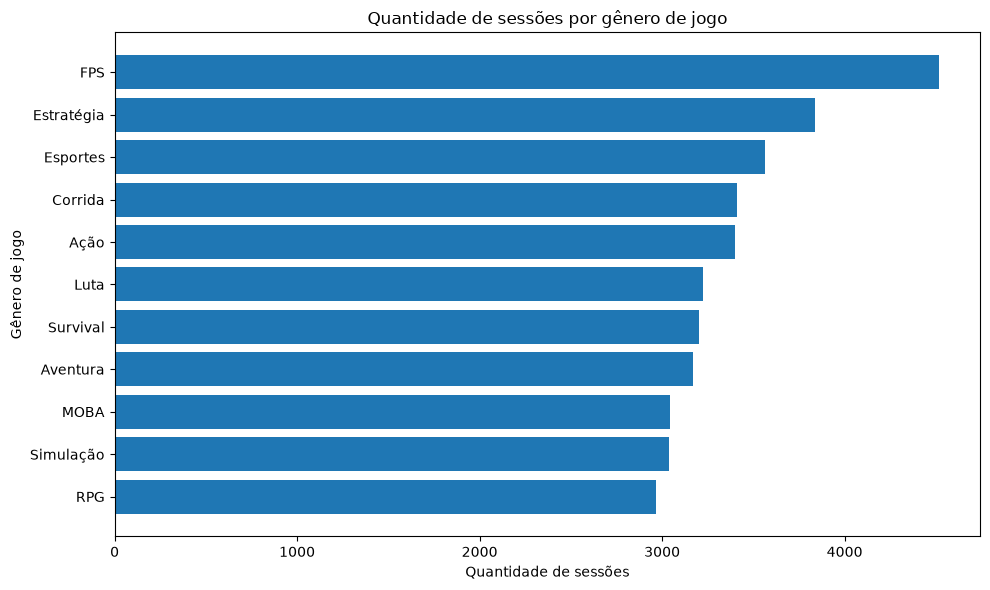

In [81]:
grafico = df_resultado_hadoop.sort_values(
    "quantidade_sessoes"
)

plt.figure(figsize=(10, 6))

plt.barh(
    grafico["genero_jogo"],
    grafico["quantidade_sessoes"]
)

plt.title("Quantidade de sessões por gênero de jogo")
plt.xlabel("Quantidade de sessões")
plt.ylabel("Gênero de jogo")

plt.tight_layout()
plt.show()


## YARN — Gerenciamento de recursos

O YARN é responsável pelo gerenciamento dos recursos computacionais do Hadoop.

In [82]:
saida_yarn, erro_yarn = comando_hadoop(
    "yarn",
    ["node", "-list"]
)

if erro_yarn is None:
    print("Consulta atual ao YARN:")
    print(saida_yarn)
else:
    print("YARN indisponível nesta execução.")
    print("A execução anterior foi concluída com sucesso.")
    print("Detalhes:", erro_yarn)

YARN indisponível nesta execução.
A execução anterior foi concluída com sucesso.
Detalhes: Hadoop não encontrado no PATH ou HADOOP_HOME


## Hive — Consultas SQL

O Apache Hive permite realizar consultas sobre grandes conjuntos de dados utilizando HiveQL, uma linguagem semelhante ao SQL.


In [83]:
conexao = sqlite3.connect(":memory:")

df_sessoes.to_sql(
    "sessoes",
    conexao,
    index=False,
    if_exists="replace"
)

print("Tabela SQL criada com sucesso.")

Tabela SQL criada com sucesso.


In [84]:
consulta_sql = """
SELECT
    genero_jogo,
    COUNT(*) AS quantidade_sessoes,
    ROUND(AVG(duracao_minutos), 2) AS duracao_media
FROM sessoes
GROUP BY genero_jogo
ORDER BY quantidade_sessoes DESC
"""

df_hive_simulado = pd.read_sql_query(
    consulta_sql,
    conexao
)

display(df_hive_simulado)

,genero_jogo,quantidade_sessoes,duracao_media
0,FPS,4516,69.71
1,Estratégia,3836,110.18
2,Esportes,3565,70.19
3,Corrida,3409,59.63
4,Ação,3397,89.99
5,Luta,3225,52.59
6,Survival,3202,166.48
7,Aventura,3168,110.67
8,MOBA,3043,88.68
9,Simulação,3040,151.08


## Pig — Transformação de dados

O Apache Pig permite construir fluxos de transformação de dados utilizando Pig Latin.


In [85]:
pig_dados = df_sessoes.copy()

# FILTER
pig_filtrado = pig_dados[
    pd.to_numeric(
        pig_dados["duracao_minutos"],
        errors="coerce"
    ) > 60
].copy()

# GROUP + FOREACH
pig_resultado = (
    pig_filtrado
    .groupby("plataforma", as_index=False)
    .agg(
        quantidade_sessoes=("sessao_id", "count"),
        duracao_media=("duracao_minutos", "mean")
    )
)

pig_resultado["duracao_media"] = (
    pig_resultado["duracao_media"].round(2)
)

display(pig_resultado)

,plataforma,quantidade_sessoes,duracao_media
0,Mobile,981,107.26
1,PC,11714,120.41
2,PlayStation,7293,122.39
3,Xbox,7619,119.89


## Sqoop — Transferência de dados

O Apache Sqoop foi desenvolvido para transferir dados entre bancos relacionais e o ecossistema Hadoop.

In [86]:
df_exportacao = pd.read_sql_query(
    """
    SELECT
        sessao_id,
        player_id,
        plataforma,
        genero_jogo,
        duracao_minutos
    FROM sessoes
    """,
    conexao
)

# Criar pasta de resultados no repositório
PASTA_RESULTADOS = (
    PROJETO / "big_data" / "hadoop" / "resultados"
)

PASTA_RESULTADOS.mkdir(
    parents=True,
    exist_ok=True
)

arquivo_exportado = (
    PASTA_RESULTADOS / "sqoop_simulado.csv"
)

# Exportar
df_exportacao.to_csv(
    arquivo_exportado,
    index=False
)

# Importar novamente
df_importacao = pd.read_csv(arquivo_exportado)

print("Registros exportados:", len(df_exportacao))
print("Registros importados:", len(df_importacao))

display(df_importacao.head())

Registros exportados: 37366
Registros importados: 37366


,sessao_id,player_id,plataforma,genero_jogo,duracao_minutos
0,1,1,PlayStation,Aventura,80
1,2,1,PC,Simulação,180
2,3,1,PlayStation,Simulação,197
3,4,1,PC,Aventura,103
4,5,1,PlayStation,Simulação,206


## HBase — Banco NoSQL

O Apache HBase é um banco NoSQL distribuído, orientado a colunas largas, que pode utilizar o HDFS como armazenamento.


In [87]:
hbase_simulado = {}

for registro in df_jogadores.to_dict("records"):
    chave = str(registro["player_id"])

    hbase_simulado[chave] = registro

print("Jogadores indexados:", len(hbase_simulado))

# Consultar o primeiro jogador disponível
if hbase_simulado:
    chave_consulta = next(iter(hbase_simulado))

    print("Chave consultada:", chave_consulta)

    display(
        pd.DataFrame([
            hbase_simulado[chave_consulta]
        ])
    )

Jogadores indexados: 1000
Chave consultada: 1


,player_id,nome,username,idade,data_nascimento,genero,cidade,estado,pais,nivel_jogador,data_criacao_conta
0,1,Kenneth Stone,kenneth.stone1,35,1991-10-22,Masculino,Union,OH,Estados Unidos,58,2026-05-17


## 9. Validação dos resultados

Para verificar a consistência da análise, comparamos a contagem de sessões realizada em Python com o resultado registrado da execução MapReduce no Hadoop.

In [88]:
print("RESUMO — PROJETO DE TELEMETRIA DE JOGOS")
print("-" * 45)

print("Sessões:", len(df_sessoes))
print("Jogadores:", len(df_jogadores))
print("Partidas:", len(df_partidas))
print("Compras:", len(df_compras))

print(
    "Gêneros:",
    df_sessoes["genero_jogo"].nunique()
)

print(
    "Sessões no resultado Hadoop:",
    df_resultado_hadoop["quantidade_sessoes"].sum()
)

print("Origem do resultado:", origem_resultado)

RESUMO — PROJETO DE TELEMETRIA DE JOGOS
---------------------------------------------
Sessões: 37366
Jogadores: 1000
Partidas: 58312
Compras: 1425
Gêneros: 11
Sessões no resultado Hadoop: 37366
Origem do resultado: Resultado histórico da execução Hadoop de 05/11/2026
